<a href="https://colab.research.google.com/github/kunjana30/Internship-Project-2/blob/main/Task2_Content_Type_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 2 (Easy) – Content Type Analysis Dashboard

**Goal:** Analyse the distribution of **Movies vs TV Shows** available on Netflix.

**Prerequisite:** run the Task 1 notebook first (it creates `netflix_cleaned.csv`).

| Step | What we do |
|------|-----------|
| 1 | Load the cleaned dataset |
| 2 | Calculate the total number of Movies and TV Shows |
| 3 | Create visualisations for content distribution |
| 4 | Compare content proportions (over time, by audience, by length) |
| 5 | Summarise key findings |

### ☁️ Google Colab / Drive setup – run this cell first
Colab's storage is **temporary**: files in `/content` disappear when the session ends, and each notebook runs in its own session.
So this cell connects to your **Google Drive** and works inside a folder called `Netflix_Analysis`, keeping `Dataset.csv`,
`netflix_cleaned.csv` (created by Task 1) and all outputs in one permanent place.

* A pop-up will ask you to allow Drive access - choose your account and click **Allow**.
* Make sure `MyDrive/Netflix_Analysis/` contains `Dataset.csv` (and `netflix_cleaned.csv` once Task 1 has been run).
* **Running locally in Jupyter?** This cell does nothing outside Colab, so you can leave it as it is.
* **No Drive?** Set `USE_DRIVE = False` and upload the files with the Files panel (folder icon on the left). They are deleted when the runtime resets.

In [ ]:
import os, sys

USE_DRIVE = True                                          # set to False to skip Google Drive
PROJECT_DIR = "/content/drive/MyDrive/Netflix_Analysis"   # the folder in your Drive that holds the project files

if "google.colab" in sys.modules and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(PROJECT_DIR, exist_ok=True)
    os.chdir(PROJECT_DIR)

print("Working folder:", os.getcwd())
print("Files here    :", sorted(os.listdir(".")))

Mounted at /content/drive
Working folder: /content/drive/MyDrive/Netflix_Analysis
Files here    : ['Dataset.csv', 'Task1_Data_Cleaning_Preparation.ipynb', 'Task2_Content_Type_Analysis.ipynb', 'Task3_Country_Wise_Analysis.ipynb', 'Task4_Trend_Analysis_Release_Year.ipynb', 'Task5_Content_Rating_Genre_Analysis.ipynb', 'Task6_Business_Insights_Report.ipynb', 'netflix_cleaned.csv', 'outputs']


---
## Step 1 – Load the cleaned dataset

In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", rc={"axes.grid.axis": "y"})
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})

# Netflix-inspired colours used consistently across every chart
NETFLIX_RED, NETFLIX_DARK, GREY = "#E50914", "#221F1F", "#B3B3B3"
TYPE_COLORS = {"Movie": NETFLIX_RED, "TV Show": NETFLIX_DARK}

CLEAN_PATH = Path("netflix_cleaned.csv")          # created by Task 1
OUT_DIR = Path("outputs/task2_content_type")                   # charts & tables are saved here (for your screenshots/report)
OUT_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    """Save the current matplotlib figure into the task's output folder."""
    plt.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

if not CLEAN_PATH.exists():
    raise FileNotFoundError("'netflix_cleaned.csv' not found. Run the Task 1 notebook first and keep this notebook in the same folder.")

In [ ]:
df = pd.read_csv(CLEAN_PATH, parse_dates=["date_added"])
print(f"Loaded {len(df):,} titles x {df.shape[1]} columns")
df.head()

Loaded 8,786 titles x 18 columns


,show_id,type,title,director,country,date_added,year_added,month_added,month_name,release_year,rating,rating_group,duration,duration_min,seasons,listed_in,n_genres,primary_genre
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2021,9,September,2020,PG-13,Teens,90 min,90.0,NaN,Documentaries,1,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,9,September,2021,TV-MA,Adults,1 Season,NaN,1.0,"Crime TV Shows, International TV Shows, TV Act...",3,Crime TV Shows
2,s11,TV Show,"Vendetta: Truth, Lies and The Mafia",Unknown,Pakistan,2021-09-24,2021,9,September,2021,TV-MA,Adults,1 Season,NaN,1.0,"Crime TV Shows, Docuseries, International TV S...",3,Crime TV Shows
3,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha",Unknown,2021-09-24,2021,9,September,2021,PG,Older Kids,91 min,91.0,NaN,Children & Family Movies,1,Children & Family Movies
4,s5,TV Show,Kota Factory,Unknown,India,2021-09-24,2021,9,September,2021,TV-MA,Adults,2 Seasons,NaN,2.0,"International TV Shows, Romantic TV Shows, TV ...",3,International TV Shows


---
## Step 2 – Calculate the total number of Movies and TV Shows

In [ ]:
total = len(df)
type_summary = df["type"].value_counts().rename_axis("type").reset_index(name="titles")
type_summary["share_%"] = (type_summary["titles"] / total * 100).round(1)

n_movie = int((df["type"] == "Movie").sum())
n_tv = int((df["type"] == "TV Show").sum())

print(f"Total titles : {total:,}")
print(f"Movies       : {n_movie:,}  ({n_movie / total:.1%})")
print(f"TV Shows     : {n_tv:,}  ({n_tv / total:.1%})")
print(f"Ratio        : {n_movie / n_tv:.2f} movies for every 1 TV show")

type_summary

Total titles : 8,786
Movies       : 6,123  (69.7%)
TV Shows     : 2,663  (30.3%)
Ratio        : 2.30 movies for every 1 TV show


,type,titles,share_%
0,Movie,6123,69.7
1,TV Show,2663,30.3


---
## Step 3 – Create visualisations for content distribution
A **bar chart** shows the absolute numbers; a **donut chart** shows each type's share of the whole. Together they answer "how many?" and "what proportion?".

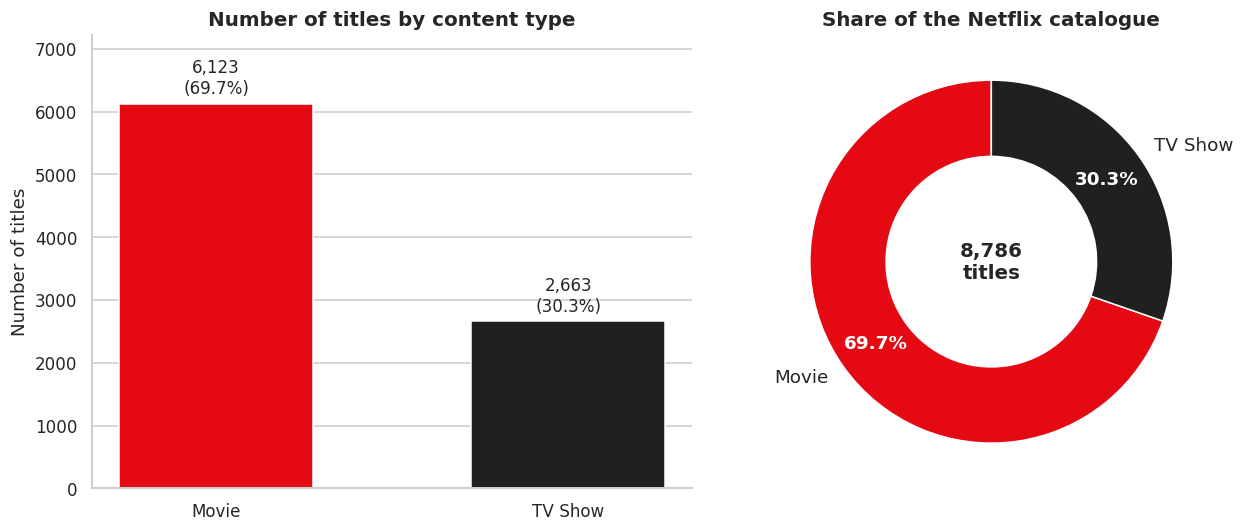

In [ ]:
order = ["Movie", "TV Show"]
counts = df["type"].value_counts().reindex(order)
colors = [TYPE_COLORS[t] for t in order]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# --- bar chart ---
bars = axes[0].bar(order, counts.values, color=colors, width=0.55)
axes[0].bar_label(bars, labels=[f"{v:,}\n({v / total:.1%})" for v in counts.values], padding=4, fontsize=11)
axes[0].set_title("Number of titles by content type")
axes[0].set_ylabel("Number of titles")
axes[0].set_ylim(0, counts.max() * 1.18)

# --- donut chart ---
wedges, texts, autotexts = axes[1].pie(
    counts.values, labels=order, colors=colors, autopct="%1.1f%%", startangle=90, pctdistance=0.78,
    wedgeprops=dict(width=0.42, edgecolor="white"), textprops={"fontsize": 12},
)
for t in autotexts:
    t.set_color("white"); t.set_fontweight("bold")
axes[1].set_title("Share of the Netflix catalogue")
axes[1].text(0, 0, f"{total:,}\ntitles", ha="center", va="center", fontsize=13, fontweight="bold")

plt.tight_layout()
save_fig("01_type_distribution")
plt.show()

---
## Step 4 – Compare content proportions
The overall split hides how the mix **changes**. We compare Movies and TV Shows:
* **over time** – by the year titles were added, and by the period they were released
* **by audience** – which maturity group each type targets
* **by length** – typical movie runtime vs number of seasons per TV show

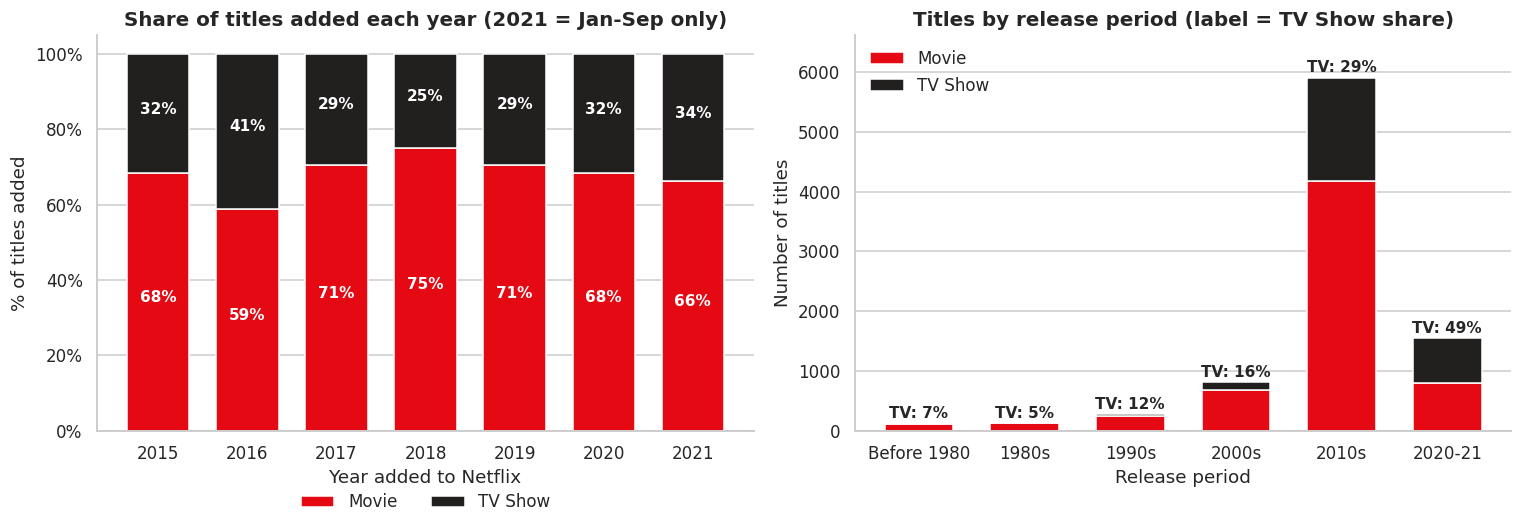

In [ ]:
# ---------- 4a. Share of additions by year (100% stacked) and 4b. Release period ----------
recent = df[df["year_added"] >= 2015]
share_added = pd.crosstab(recent["year_added"], recent["type"], normalize="index")[order] * 100
counts_added = pd.crosstab(recent["year_added"], recent["type"])[order]

periods = pd.cut(df["release_year"], bins=[1924, 1979, 1989, 1999, 2009, 2019, 2021],
                 labels=["Before 1980", "1980s", "1990s", "2000s", "2010s", "2020-21"])
by_period = pd.crosstab(periods, df["type"])[order]
tv_share_period = by_period["TV Show"] / by_period.sum(axis=1) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 4a
bottom = np.zeros(len(share_added))
for t in order:
    axes[0].bar(share_added.index.astype(str), share_added[t], bottom=bottom, color=TYPE_COLORS[t], label=t, width=0.7)
    bottom += share_added[t].values
for i, (yr, row) in enumerate(share_added.iterrows()):
    axes[0].text(i, row["Movie"] / 2, f"{row['Movie']:.0f}%", ha="center", color="white", fontsize=10, fontweight="bold")
    axes[0].text(i, row["Movie"] + row["TV Show"] / 2, f"{row['TV Show']:.0f}%", ha="center", color="white", fontsize=10, fontweight="bold")
axes[0].set_title("Share of titles added each year (2021 = Jan-Sep only)")
axes[0].set_xlabel("Year added to Netflix"); axes[0].set_ylabel("% of titles added")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)

# 4b
x = np.arange(len(by_period))
axes[1].bar(x, by_period["Movie"], color=NETFLIX_RED, label="Movie", width=0.65)
axes[1].bar(x, by_period["TV Show"], bottom=by_period["Movie"], color=NETFLIX_DARK, label="TV Show", width=0.65)
for i, share in enumerate(tv_share_period):
    axes[1].text(i, by_period.iloc[i].sum() + by_period.sum(axis=1).max() * 0.015, f"TV: {share:.0f}%", ha="center", fontsize=10, fontweight="bold")
axes[1].set_xticks(x); axes[1].set_xticklabels(by_period.index)
axes[1].set_title("Titles by release period (label = TV Show share)")
axes[1].set_xlabel("Release period"); axes[1].set_ylabel("Number of titles")
axes[1].set_ylim(0, by_period.sum(axis=1).max() * 1.12); axes[1].legend(frameon=False)

plt.tight_layout()
save_fig("02_type_share_over_time")
plt.show()

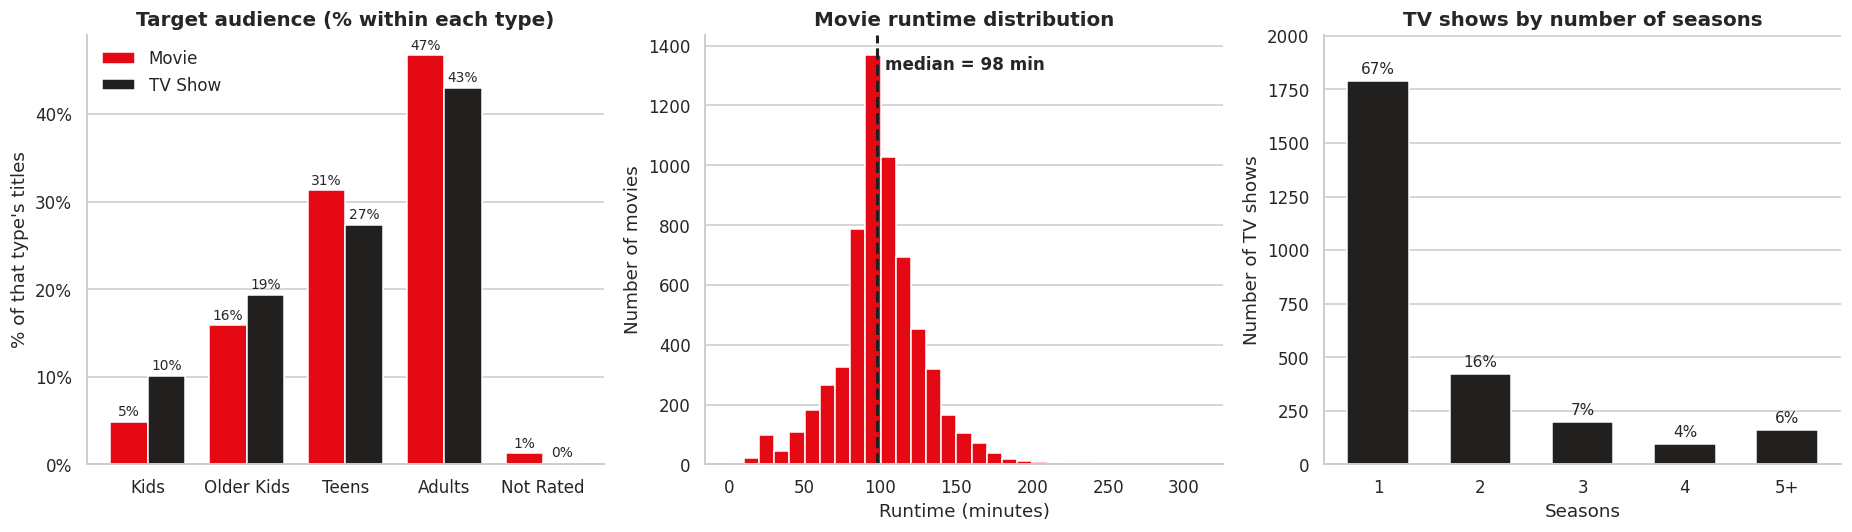

In [ ]:
# ---------- 4c. Audience group by type, 4d. Movie runtime, 4e. TV seasons ----------
group_order = ["Kids", "Older Kids", "Teens", "Adults", "Not Rated"]
audience = (pd.crosstab(df["rating_group"], df["type"], normalize="columns")[order] * 100).reindex(group_order)

movie_runtime = df.loc[df["type"] == "Movie", "duration_min"].dropna()
seasons = df.loc[df["type"] == "TV Show", "seasons"].dropna().astype(int)
season_dist = seasons.clip(upper=5).value_counts().sort_index()          # 5 = "5 or more"
season_labels = [str(i) if i < 5 else "5+" for i in season_dist.index]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 4c grouped bars
x = np.arange(len(group_order)); w = 0.38
for k, t in enumerate(order):
    b = axes[0].bar(x + (k - 0.5) * w, audience[t], width=w, color=TYPE_COLORS[t], label=t)
    axes[0].bar_label(b, fmt="%.0f%%", fontsize=9, padding=2)
axes[0].set_xticks(x); axes[0].set_xticklabels(group_order)
axes[0].set_title("Target audience (% within each type)"); axes[0].set_ylabel("% of that type's titles")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); axes[0].legend(frameon=False)

# 4d runtime
axes[1].hist(movie_runtime, bins=range(0, 320, 10), color=NETFLIX_RED, edgecolor="white")
axes[1].axvline(movie_runtime.median(), color=NETFLIX_DARK, linestyle="--", linewidth=2)
axes[1].text(movie_runtime.median() + 5, axes[1].get_ylim()[1] * 0.92, f"median = {movie_runtime.median():.0f} min", fontsize=11, fontweight="bold")
axes[1].set_title("Movie runtime distribution"); axes[1].set_xlabel("Runtime (minutes)"); axes[1].set_ylabel("Number of movies")

# 4e seasons
b = axes[2].bar(season_labels, season_dist.values, color=NETFLIX_DARK, width=0.6)
axes[2].bar_label(b, labels=[f"{v / season_dist.sum():.0%}" for v in season_dist.values], padding=3, fontsize=10)
axes[2].set_title("TV shows by number of seasons"); axes[2].set_xlabel("Seasons"); axes[2].set_ylabel("Number of TV shows")
axes[2].set_ylim(0, season_dist.max() * 1.12)

plt.tight_layout()
save_fig("03_audience_runtime_seasons")
plt.show()

---
## Step 5 – Summarise key findings
The findings below are **generated from the data with f-strings**, so every number is guaranteed to match your charts.
Rewrite them in your own words in your report.

In [ ]:
tv_since_2016 = share_added.loc[2016:, "TV Show"]
latest_year = int(share_added.index.max())
tv_share_latest = share_added.loc[latest_year, "TV Show"]

kids_movie = audience.loc[["Kids", "Older Kids"], "Movie"].sum()
kids_tv = audience.loc[["Kids", "Older Kids"], "TV Show"].sum()
adult_movie, adult_tv = audience.loc["Adults", "Movie"], audience.loc["Adults", "TV Show"]

findings = [
    f"**Movies dominate the catalogue.** Netflix lists {total:,} titles: {n_movie:,} Movies ({n_movie / total:.1%}) and {n_tv:,} TV Shows ({n_tv / total:.1%}) - about {n_movie / n_tv:.1f} movies for every TV show.",
    f"**TV Shows take a bigger slice of recent releases.** They made up {tv_share_period['2000s']:.0f}% of titles released in the 2000s, {tv_share_period['2010s']:.0f}% in the 2010s and {tv_share_period['2020-21']:.0f}% of 2020-21 releases.",
    f"**The mix of new additions moves around a lot.** Since 2016 the TV Show share of titles added each year has ranged from {tv_since_2016.min():.0f}% ({tv_since_2016.idxmin()}) to {tv_since_2016.max():.0f}% ({tv_since_2016.idxmax()}); in {latest_year} (Jan-Sep) it is {tv_share_latest:.0f}%.",
    f"**TV Shows lean more towards younger viewers.** {kids_tv:.0f}% of TV titles are rated for Kids/Older Kids versus {kids_movie:.0f}% of movies, while {adult_movie:.0f}% of movies and {adult_tv:.0f}% of TV shows are Adult-rated.",
    f"**Length profile.** The median movie runs {movie_runtime.median():.0f} minutes, and {(seasons == 1).mean():.0%} of TV shows have only one season (so many are new or limited series).",
]
display(Markdown("\n\n".join(f"{i}. {f}" for i, f in enumerate(findings, 1))))

# save the summary table for your report
type_summary.to_csv(OUT_DIR / "type_summary.csv", index=False)
by_period.assign(tv_share_pct=tv_share_period.round(1)).to_csv(OUT_DIR / "type_by_release_period.csv")

1. **Movies dominate the catalogue.** Netflix lists 8,786 titles: 6,123 Movies (69.7%) and 2,663 TV Shows (30.3%) - about 2.3 movies for every TV show.

2. **TV Shows take a bigger slice of recent releases.** They made up 16% of titles released in the 2000s, 29% in the 2010s and 49% of 2020-21 releases.

3. **The mix of new additions moves around a lot.** Since 2016 the TV Show share of titles added each year has ranged from 25% (2018) to 41% (2016); in 2021 (Jan-Sep) it is 34%.

4. **TV Shows lean more towards younger viewers.** 29% of TV titles are rated for Kids/Older Kids versus 21% of movies, while 47% of movies and 43% of TV shows are Adult-rated.

5. **Length profile.** The median movie runs 98 minutes, and 67% of TV shows have only one season (so many are new or limited series).

### Interpretation notes (add your own thoughts)
* **Why does this matter?** The Movie/TV split affects how Netflix balances licensing costs (movies) against long-term subscriber retention (series with multiple seasons).
* **Caveat:** this dataset is a snapshot of the catalogue up to **Sept 2021** and counts *titles*, not viewing hours – a TV show with 5 seasons counts once.

---
## ✅ Summary
Calculated totals, visualised the distribution (bar + donut), compared proportions over time, by audience and by length,
and summarised the findings. Charts are saved in `outputs/task2_content_type/` – use them for your screenshots.